# 🩺 Predicción de Riesgo de Enfermedad Cardiovascular
**Autor:** Jorge Sánchez Hernández  
**Proyecto:** Machine Learning supervisado  
**Datos:** Encuesta de Salud España 2025 *(Ministerio de Sanidad)*

## 3. Entrenamiento y evaluación

Cargamos las librerias que vayamos a utilizar

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, RocCurveDisplay
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_predict
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

RANDOM_STATE = 42

#Como de desbalanceada esta nuestra muestra?
df = pd.read_csv("../data/processed/ecv_procesado.csv")
print(df.shape)                                   # (20016, 42)
print(df["ecv"].value_counts(normalize=True).round(3))

(20357, 42)
ecv
0    0.899
1    0.101
Name: proportion, dtype: float64


Agrupamos las columnas para entrenar nuestro modelo

In [2]:


cols_riesgo = ["tension_alta", "colesterol_alto", "diabetes", "epoc", "problemas_rinon",
               "migrana", "tumor_maligno", "depresion", "ansiedad", "otros_problemas_mentales"]
cols_dieta = ["dieta_fruta", "dieta_verdura", "dieta_legumbres", "dieta_pescado",
              "dieta_carne_procesada", "dieta_dulces", "dieta_refrescos",
              "dieta_comida_rapida", "dieta_aperitivos"]

cols_num = ["edad", "imc", "sentado_h", "cigarrillos_dia",
            "dias_camina", "dias_deporte", "dias_fuerza"]
cols_bin = ["mujer"]
cols_cat = (cols_riesgo + cols_dieta +
            ["nivel_estudios", "clase_social", "ejercicio_ocio", "severidad_depresiva",
             "apoyo_personas", "fuma", "frec_alcohol", "frec_atracon_alcohol",
             "actividad_trabajo", "vapeo", "humo_ajeno", "imc_categoria", "ccaa"])


Hacemos nuestro split y guardamos

In [3]:
X = df.drop(columns=["ecv", "factor"])      # factor = peso de la encuesta lo hemos utilizado en el EDA, no es predictor
y = df["ecv"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print(X_train.shape, X_test.shape)         
print(y_train.mean().round(3), y_test.mean().round(3))   #Tienen q ser 0.1

# Guardamos los conjuntos 
X_train.assign(ecv=y_train).to_csv("../data/train/train.csv", index=False)
X_test.assign(ecv=y_test).to_csv("../data/test/test.csv", index=False)

(16285, 40) (4072, 40)
0.101 0.101


Establecemos como va a ser el preprocesado. Establecemos pipelines

In [4]:
rama_num = Pipeline([("imputar", SimpleImputer(strategy="median")),
                     ("escalar", StandardScaler())])
rama_cat = Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                     ("onehot", OneHotEncoder(handle_unknown="ignore"))])

preprocesador = ColumnTransformer([("num", rama_num, cols_num),
                                   ("bin", "passthrough", cols_bin),
                                   ("cat", rama_cat, cols_cat)])

Comprobamos que funciona. Luego no lo utilizamos

In [5]:

X_prueba = preprocesador.fit_transform(X_train)
print(X_prueba.shape)        # (16012, ~198): 7 numéricas + 1 binaria + ~190 del one-hot

print("Accuracy de predecir siempre 0 (que nadie tiene ECV):", round(1 - y_test.mean(), 3)) 

(16285, 167)
Accuracy de predecir siempre 0 (que nadie tiene ECV): 0.899


------

Vamos a instanciar los modelos. Tenemos que probar cinco modelos y elegir el mejor.

**1. Regresión logística**

In [6]:
SCORING = "f1"     # métrica para elegir hiperparámetros (alternativas: "recall", "roc_auc")
CV = 5

pipe_lr = Pipeline([("prep", preprocesador),
                    ("modelo", LogisticRegression(class_weight="balanced", max_iter=1000,
                                                  random_state=RANDOM_STATE))])

cv_f1 = cross_val_score(pipe_lr, X_train, y_train, cv=CV, scoring="f1")
cv_recall = cross_val_score(pipe_lr, X_train, y_train, cv=CV, scoring="recall")
print("Regresión Logística | F1 CV:", cv_f1.mean().round(3), "| Recall CV:", cv_recall.mean().round(3))

pipe_lr.fit(X_train, y_train)

Regresión Logística | F1 CV: 0.353 | Recall CV: 0.722


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](40,)","['ccaa','edad','nivel_estudios',...,'severidad_depresiva','mujer','imc']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,40
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('bin', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all r

**2.Árboles de decision** (DecisionTree: dt)

In [7]:
#dt = decision tree
pipe_dt = Pipeline([("prep", preprocesador),
                    ("modelo", DecisionTreeClassifier(class_weight="balanced",
                                                      random_state=RANDOM_STATE))])
grid_dt = GridSearchCV(pipe_dt,
                       {"modelo__max_depth": [3, 5, 8, 12],
                        "modelo__min_samples_leaf": [5, 20, 50]},
                       cv=CV, scoring=SCORING, n_jobs=-1)
grid_dt.fit(X_train, y_train)
print("Árbol:", grid_dt.best_params_, "|", SCORING, "CV:", round(grid_dt.best_score_, 3))

Árbol: {'modelo__max_depth': 3, 'modelo__min_samples_leaf': 5} | f1 CV: 0.344


**3. Random Forest** (rf)

In [8]:

pipe_rf = Pipeline([("prep", preprocesador),
                    ("modelo", RandomForestClassifier(class_weight="balanced",
                                                      random_state=RANDOM_STATE))])
grid_rf = GridSearchCV(pipe_rf,
                       {"modelo__n_estimators": [100, 200],
                        "modelo__max_depth": [5, 10, None],
                        "modelo__min_samples_leaf": [1, 5, 10]},
                       cv=CV, scoring=SCORING, n_jobs=-1)
grid_rf.fit(X_train, y_train)
print("Random Forest:", grid_rf.best_params_, "|", SCORING, "CV:", round(grid_rf.best_score_, 3))

Random Forest: {'modelo__max_depth': None, 'modelo__min_samples_leaf': 5, 'modelo__n_estimators': 200} | f1 CV: 0.38


**4. XGBoost** (xgb)

In [9]:
peso_positivo = (y_train == 0).sum() / (y_train == 1).sum()     # compensa el desbalanceo
print("scale_pos_weight:", round(peso_positivo, 2))

pipe_xgb = Pipeline([("prep", preprocesador),
                     ("modelo", XGBClassifier(scale_pos_weight=peso_positivo, eval_metric="logloss",
                                              random_state=RANDOM_STATE))])
rand_xgb = RandomizedSearchCV(pipe_xgb,
                              {"modelo__n_estimators": [100, 200, 300],
                               "modelo__max_depth": [3, 5, 7],
                               "modelo__learning_rate": [0.01, 0.05, 0.1],
                               "modelo__subsample": [0.7, 0.9, 1.0]},
                              n_iter=10, cv=CV, scoring=SCORING,
                              random_state=RANDOM_STATE, n_jobs=-1)
rand_xgb.fit(X_train, y_train)
print("XGBoost:", rand_xgb.best_params_, "|", SCORING, "CV:", round(rand_xgb.best_score_, 3))

scale_pos_weight: 8.91
XGBoost: {'modelo__subsample': 0.7, 'modelo__n_estimators': 100, 'modelo__max_depth': 7, 'modelo__learning_rate': 0.01} | f1 CV: 0.368


**5. K-Nearest Neighbors** (KNN)

In [10]:
pipe_knn = Pipeline([("prep", preprocesador),
                     ("modelo", KNeighborsClassifier())])
grid_knn = GridSearchCV(pipe_knn,
                        {"modelo__n_neighbors": [5, 15, 31],
                         "modelo__weights": ["uniform", "distance"]},
                        cv=CV, scoring=SCORING, n_jobs=-1)
grid_knn.fit(X_train, y_train)
print("KNN:", grid_knn.best_params_, "|", SCORING, "CV:", round(grid_knn.best_score_, 3))

KNN: {'modelo__n_neighbors': 5, 'modelo__weights': 'uniform'} | f1 CV: 0.105


----

Comparacion de los modelos: 

,Accuracy,Precision,Recall,F1,ROC AUC
Modelo,,,,,
Regresión Logística,0.735,0.236,0.727,0.357,0.787
Árbol de decisión,0.744,0.235,0.679,0.349,0.750
Random Forest,0.799,0.270,0.579,0.368,0.787
XGBoost,0.756,0.245,0.679,0.360,0.781
KNN,0.893,0.329,0.056,0.096,0.624


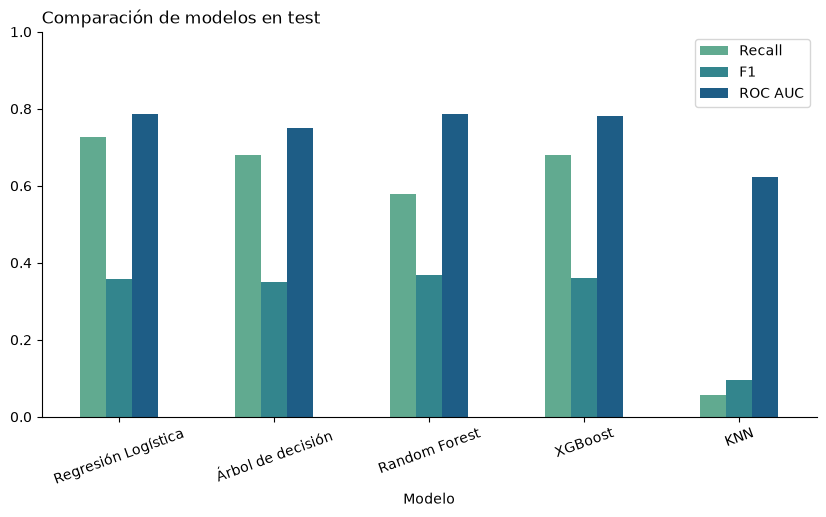

In [11]:
modelos = {"Regresión Logística": pipe_lr,
           "Árbol de decisión": grid_dt.best_estimator_,
           "Random Forest": grid_rf.best_estimator_,
           "XGBoost": rand_xgb.best_estimator_,
           "KNN": grid_knn.best_estimator_}

filas = []
for nombre, m in modelos.items():
    pred = m.predict(X_test)
    proba = m.predict_proba(X_test)[:, 1]
    filas.append({"Modelo": nombre,
                  "Accuracy": accuracy_score(y_test, pred),
                  "Precision": precision_score(y_test, pred),
                  "Recall": recall_score(y_test, pred),
                  "F1": f1_score(y_test, pred),
                  "ROC AUC": roc_auc_score(y_test, proba)})
tabla = pd.DataFrame(filas).set_index("Modelo").round(3)
display(tabla)

tabla[["Recall", "F1", "ROC AUC"]].plot(kind="bar", figsize=(10, 5),
                                        color=sns.color_palette("crest", 3))
plt.title("Comparación de modelos en test", loc="left")
plt.ylim(0, 1)
plt.xticks(rotation=20)
sns.despine()
plt.show()

Los tres primeros están muy cerca.
ROC AUC: 0,783 la Regresión Logística, 0,781 Random Forest y 0,777 XGBoost.
F1: 0,349, 0,363 y 0,360.
Con diferencias de 0,006 en AUC y 0,014 en F1, es un empate práctico.
La Regresión Logística detecta más enfermos. Su recall (0,704) es el más alto, y su AUC también. Random Forest tiene mejor precisión, pero deja escapar a casi la mitad de los enfermos (recall 0,551).
El Árbol de decisión es peor (AUC 0,749), como suele pasar con un árbol solo.
KNN no sirve, pero es instructivo. Su accuracy (0,891) parece la mejor, pero casi iguala el baseline trivial de decir siempre "sano" (0,90). Con un recall de 0,040, prácticamente no detecta a nadie. Nos muestra por qué la accuracy engaña aquí.

Seleccionamos el modelo de la regresión logística

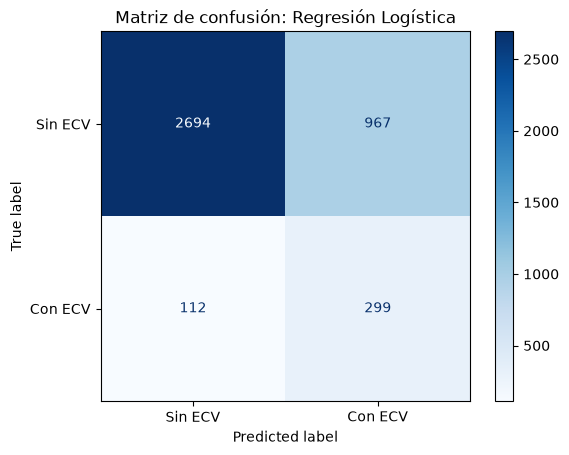

              precision    recall  f1-score   support

     Sin ECV       0.96      0.74      0.83      3661
     Con ECV       0.24      0.73      0.36       411

    accuracy                           0.74      4072
   macro avg       0.60      0.73      0.59      4072
weighted avg       0.89      0.74      0.79      4072



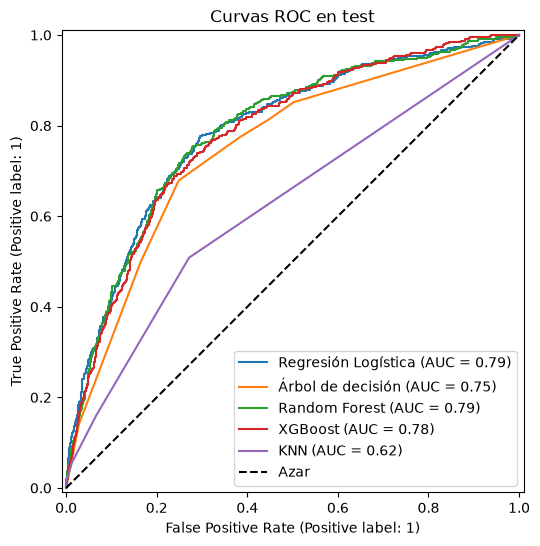

In [12]:
nombre_final = "Regresión Logística"          
modelo_final = modelos[nombre_final]
pred_final = modelo_final.predict(X_test)

ConfusionMatrixDisplay.from_predictions(y_test, pred_final,
                                        display_labels=["Sin ECV", "Con ECV"], cmap="Blues")
plt.title(f"Matriz de confusión: {nombre_final}")
plt.show()
print(classification_report(y_test, pred_final, target_names=["Sin ECV", "Con ECV"]))

# Curvas ROC de los 5 modelos
fig, ax = plt.subplots(figsize=(7, 6))
for nombre, m in modelos.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, name=nombre, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Azar")
ax.legend()
plt.title("Curvas ROC en test")
plt.show()

La importancia de las variables 

frec_atracon_alcohol    1.038
edad                    0.683
mujer                   0.610
dieta_comida_rapida     0.551
ccaa                    0.457
tension_alta            0.414
dieta_fruta             0.347
diabetes                0.314
actividad_trabajo       0.310
severidad_depresiva     0.299
frec_alcohol            0.287
epoc                    0.266
problemas_rinon         0.257
colesterol_alto         0.246
dieta_aperitivos        0.246
dtype: float64


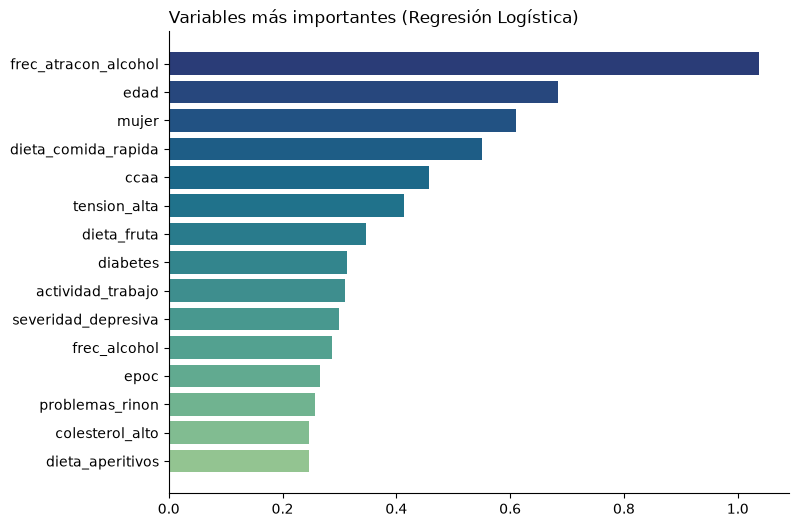

In [15]:
nombres_cols = modelo_final["prep"].get_feature_names_out()
paso = modelo_final["modelo"]
valores = paso.feature_importances_ if hasattr(paso, "feature_importances_") else np.abs(paso.coef_[0])
importancias = pd.Series(valores, index=nombres_cols)

# El one-hot reparte una variable en varias columnas: las sumamos de nuevo
def variable_original(nombre):
    nombre = nombre.split("__", 1)[1]                    # quita num__, bin__ o cat__
    for col in sorted(X.columns, key=len, reverse=True):    # primero los nombres más largos
        if nombre == col or nombre.startswith(col + "_"):
            return col

por_variable = importancias.groupby(variable_original).max().sort_values(ascending=False)
print(por_variable.head(15).round(3))

top = por_variable.head(15)[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top.index, top.values, color=sns.color_palette("crest", len(top)))
plt.title(f"Variables más importantes ({nombre_final})", loc="left")
sns.despine()
plt.show()

In [16]:
probar_cv = cross_val_predict(modelo_final, X_train, y_train, cv=CV, method="predict_proba")[:, 1]
for u in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    pred_u = (probar_cv >= u).astype(int)
    print(f"umbral {u}: recall {recall_score(y_train, pred_u):.2f} | precision {precision_score(y_train, pred_u):.2f}")

umbral = 0.2       
pred_test = (modelo_final.predict_proba(X_test)[:, 1] >= umbral).astype(int)
print("\nEn test con ese umbral:")
print("Recall:", round(recall_score(y_test, pred_test), 3),
      "| Precision:", round(precision_score(y_test, pred_test), 3),
      "| F1:", round(f1_score(y_test, pred_test), 3))

umbral 0.2: recall 0.94 | precision 0.14
umbral 0.3: recall 0.88 | precision 0.17
umbral 0.4: recall 0.82 | precision 0.20
umbral 0.5: recall 0.72 | precision 0.23
umbral 0.6: recall 0.62 | precision 0.27
umbral 0.7: recall 0.48 | precision 0.32
umbral 0.8: recall 0.30 | precision 0.38

En test con ese umbral:
Recall: 0.929 | Precision: 0.139 | F1: 0.242



**Umbral 0.2:** 0.93 recall 0.14 precision. 	Cribado poblacional amplio: Detecta a 93 de cada 100 pacientes en riesgo real. Los falsos positivos (86 de cada 100 alertas) recibirán consejos de estilo de vida y chequeos básicos, lo cual no les es dañino.


EXTRA -- UMBRALES DIFERENTES SEGUN RIESGO

In [ ]:
# --- ESTRATIFICACIÓN POR NIVELES DE RIESGO EN TEST ---

# 1. Obtenemos las probabilidades usando la regresion logistica
probabilidades = modelo_final.predict_proba(X_test)[:, 1]

# 2. Definimos los 3 grupos usando 0.2 y 0.5 como cortes
condiciones = [
    (probabilidades < 0.2),
    (probabilidades >= 0.2) & (probabilidades < 0.5),
    (probabilidades >= 0.5)
]
niveles = ["1. Riesgo Bajo (< 0.2)", "2. Riesgo Moderado (0.2 - 0.5)", "3. Riesgo Alto (>= 0.5)"]

# 3. Clasificamos a los 4.004 pacientes de test
df_riesgo = pd.DataFrame({
    "Probabilidad": probabilidades,
    "Nivel_Riesgo": np.select(condiciones, niveles, default="Desconocido"),
    "ECV_Real": y_test.values
})

# 4. Tabla resumen para comprobar cuántos casos reales caen en cada nivel
resumen_riesgo = df_riesgo.groupby("Nivel_Riesgo").agg(
    Total_Pacientes=("ECV_Real", "count"),
    Casos_ECV_Reales=("ECV_Real", "sum"),
    Prevalencia_Real=("ECV_Real", "mean")
)
resumen_riesgo["% Pacientes"] = (resumen_riesgo["Total_Pacientes"] / len(df_riesgo) * 100).round(1)
resumen_riesgo["% ECV Real"] = (resumen_riesgo["Prevalencia_Real"] * 100).round(2)

display(resumen_riesgo[["Total_Pacientes", "% Pacientes", "Casos_ECV_Reales", "% ECV Real"]])


,Total_Pacientes,% Pacientes,Casos_ECV_Reales,% ECV Real
Nivel_Riesgo,,,,
1. Riesgo Bajo (< 0.2),1344,33.6,35,2.60
2. Riesgo Moderado (0.2 - 0.5),1449,36.2,83,5.73
3. Riesgo Alto (>= 0.5),1211,30.2,281,23.20


/var/folders/pr/c0xf4wvs7xz313lcynwg4pn80000gp/T/ipykernel_70910/2585371854.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=resumen_riesgo.index, y=resumen_riesgo["% ECV Real"], palette=["#2ecc71", "#f39c12", "#e74c3c"])


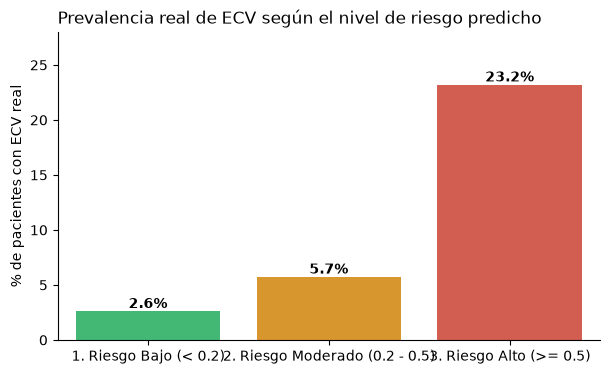

In [ ]:
plt.figure(figsize=(7, 4))
ax = sns.barplot(x=resumen_riesgo.index, y=resumen_riesgo["% ECV Real"], palette=["#2ecc71", "#f39c12", "#e74c3c"])
plt.title("Prevalencia real de ECV según el nivel de riesgo predicho", loc="left")
plt.ylabel("% de pacientes con ECV real")
plt.xlabel("")
plt.ylim(0, 28)

for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha="center", va="bottom", fontweight="bold")

sns.despine()
plt.show()
